---

# Curso: Data Mining - Semana 12

# Geopandas


Docente: Soledad Espezúa (s.espezual@up.edu.pe)

---

In [2]:
# Importa algunas librerias base
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
#import warnings
#warnings.filterwarnings("ignore")   # para evitar que muestre constantemente advertencias

#**Introducción a Datos Geoespaciales**



Los datos geoespaciales se refieren a **información que puede asociarse con ubicaciones geográficas en la Tierra**. Vienen con atributos espaciales como ubicación y forma geométrica.

Ejemplos de datos geoespaciales:
* Densidad poblacional
* Información de clima y temperatura
* Redes de transporte

Otros ejemplos comunes incluyen:
* Límites administrativos (distritos, provincias)
* Uso de suelo (zonas agrícolas, urbanas)
* Recursos naturales (ríos, lagos, bosques)
* Infraestructura (escuelas, hospitales, parques)
* Servicios públicos (agua, luz, desagüe)
* Elevación del terreno
* Rutas de transporte público
* Zonas de riesgo


In [3]:
# Importa libreria geopandas como gpd
import geopandas as gpd

Los datos geoespaciales pueden representarse de dos formas:
* **Vector**: usando geometrías como puntos, líneas y polígonos. Cada geometría puede tener múltiples atributos asociados. Se suelen guardar en formatos como `Shapefile` (.shp) o `GeoJSON`.
* **Raster**: usando una cuadrícula como una imagen, donde cada celda tiene un valor que representa una medición. Se suelen guardar en formatos como `GeoTIFF` o `NetCDF`

**Introducción a Datos Vectoriales**
Para trabajar con geometrías en Python se usara principalmente:

* shapely: biblioteca básica para crear y manipular objetos geométricos
* geopandas: biblioteca de alto nivel que normalmente será suficiente para la mayoría de casos

shapely te permite trabajar con:

* Relaciones espaciales (si un punto está dentro de un área)
* Operaciones geométricas (unir dos áreas)
* Transformaciones de coordenadas (cambiar sistema de referencia)

Las geometrías básicas son:

* Punto: una ubicación específica (x,y)
* Línea: varios puntos conectados
* Polígono: área cerrada definida por puntos

Veamos cómo crear un punto:

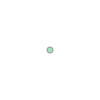

In [4]:
from shapely.geometry import Point

# Crea un punto
point = Point(1,2)
point

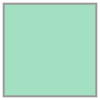

In [ ]:
from shapely.geometry import Polygon

points = [(0,0), (0,2), (2,2), (2,0)] # Shapely cierra automáticamente el polígono
polygon = Polygon(points)
polygon



```
(0,2) -------- (2,2)
  |              |
  |              |
  |              |
(0,0) -------- (2,0)
```

Múltiples geometrias

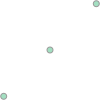

In [ ]:
from shapely.geometry import MultiPoint
points = [Point(0, 0), Point(1, 1), Point(2, 2)]
multipoint = MultiPoint(points)
multipoint

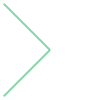

In [ ]:
from shapely.geometry import  MultiLineString, LineString
linestrings = [LineString([(0, 0), (1, 1)]), LineString([(1, 1), (0, 2)])]
multiline = MultiLineString(linestrings)
multiline

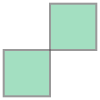

In [ ]:
from shapely.geometry import MultiPolygon
polygons = [Polygon([(0, 0), (0, 1), (1, 1), (1, 0)]), Polygon([(1, 1), (1, 2), (2, 2), (2, 1)])]
multipolygon = MultiPolygon(polygons)
multipolygon

In [ ]:
from shapely.geometry import Point, MultiPoint, Polygon,  MultiPolygon, LineString, MultiLineString

### Propiedades de Objetos Geometricos

* **area**: devuelve la superficie de la geometría. En polígonos y multipolígonos es el área encerrada; en puntos y líneas el área es 0.
* **length**: devuelve la longitud. En un polígono es su **perímetro** (la suma de sus lados); en una línea, su largo.
* **bounds**: devuelve las coordenadas de la **caja envolvente**: el rectángulo más pequeño que contiene completamente a la geometría, como una tupla (x_mínimo, y_mínimo, x_máximo, y_máximo). No es una medida: son las esquinas de ese rectángulo.
* **centroid**: devuelve el centroide de la geometría, es decir, su centro geométrico o punto de equilibrio, como un objeto Point.

Usaremos el mismo polígono irregular para ver las cuatro propiedades.

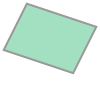

In [ ]:
from shapely.geometry import Polygon, box

# Polígono irregular (el mismo de la diapositiva)
polygon = Polygon([(1, 2), (2, 4), (5, 3), (4, 1)])
polygon

In [ ]:
# Área del polígono (superficie)
polygon.area

7.0

In [ ]:
# Perímetro del polígono: suma de las longitudes de sus 4 lados
# En shapely el perímetro se llama length
polygon.length

10.79669127533634

minx: 1.0, miny: 1.0, maxx: 5.0, maxy: 4.0
x_poly: array('d', [1.0, 2.0, 5.0, 4.0, 1.0]), y_poly: array('d', [2.0, 4.0, 3.0, 1.0, 2.0])
x_box: array('d', [5.0, 5.0, 1.0, 1.0, 5.0]), y_box: array('d', [1.0, 4.0, 4.0, 1.0, 1.0])


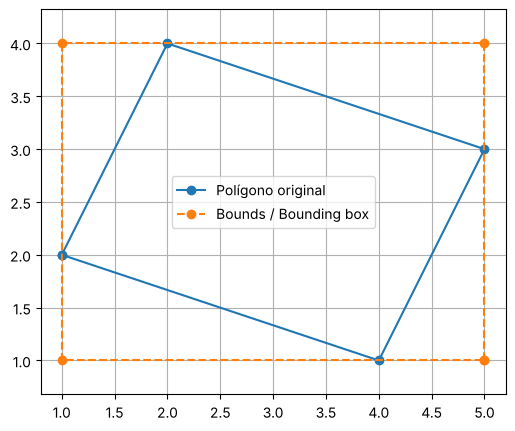

In [ ]:
#bounds devuelve las coordenadas extremas de una geometría
minx, miny, maxx, maxy = polygon.bounds
print(f"minx: {minx}, miny: {miny}, maxx: {maxx}, maxy: {maxy}")

#-------Visualizar el bound-->opcional---------------

# box usa las coordenadas para construir un poligono rectangular
bbox = box(minx, miny, maxx, maxy)   # es lo mismo que polygon.envelope

# Extrae las coordenadas del borde exterior del polígono, separadas en dos arreglos
x_poly, y_poly = polygon.exterior.xy # Coordenadas del polígono original
print(f"x_poly: {x_poly}, y_poly: {y_poly}")

x_box, y_box = bbox.exterior.xy  # Coordenadas del bounding box
print(f"x_box: {x_box}, y_box: {y_box}")

# Graficar
plt.figure(figsize=(6, 5))

plt.plot(x_poly, y_poly, marker="o", label="Polígono original")
plt.plot(x_box, y_box, linestyle="--", marker="o", label="Bounds / Bounding box")

plt.legend()
plt.axis("equal")
plt.grid(True)
plt.show()

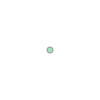

In [ ]:
# Centroide de un Poligono
polygon_centroid = polygon.centroid
polygon_centroid

In [ ]:
#obtiene las coordenadas x e y del centroide del polígono
polygon_centroid.x, polygon_centroid.y

(3.0, 2.5)

In [ ]:
#obtiene las coordenadas del centroide como una tupla
(x_del_centroide, y_del_centroide) = polygon_centroid.coords[0]
print(x_del_centroide, y_del_centroide)

3.0 2.5


In [ ]:
#devuelve las coordenadas del centroide en forma de dos arreglos
polygon_centroid.xy

(array('d', [3.0]), array('d', [2.5]))

### Operaciones

Las operaciones combinan dos geometrías y **devuelven una geometría nueva**:

* **union**: une dos objetos geométricos
* **intersection**: encuentra el área común entre dos objetos
* **difference**: calcula lo que queda del primer objeto al quitarle el segundo

polygon1 area: 4.0, polygon2 area: 4.0, polygon_union area: 7.0


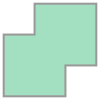

In [ ]:
# Crea dos objetos poligonos
polygon1 = Polygon([(0, 0), (0, 2), (2, 2), (2, 0)])
polygon2 = Polygon([(1, 1), (1, 3), (3, 3), (3, 1)])

# Union de dos poligonos
polygon_union = polygon1.union(polygon2)
print(f"polygon1 area: {polygon1.area}, polygon2 area: {polygon2.area}, polygon_union area: {polygon_union.area}")
polygon_union

area polygon1: 4.0, area polygon2: 4.0, area polygon_intersection: 1.0


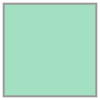

In [ ]:
# Interseccion de dos poligonos
polygon_intersection = polygon1.intersection(polygon2)
print(f"area polygon1: {polygon1.area}, area polygon2: {polygon2.area}, area polygon_intersection: {polygon_intersection.area}")
polygon_intersection


area polygon1: 4.0,area polygon2:4.0,area polygon_difference: 3.0


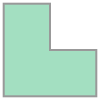

In [ ]:
# Diferencia de dos poligonos
polygon_difference=polygon1.difference(polygon2)
print(f"area polygon1: {polygon1.area},area polygon2:{polygon2.area},area polygon_difference: {polygon_difference.area}")
polygon_difference

### Relaciones de objetos geoespaciales

Las relaciones responden una pregunta y **devuelven True o False**:

* **equals**: ¿son la misma geometría?
* **within**: ¿A está dentro de B?
* **contains**: ¿A contiene a B? (es lo inverso de within)
* **intersects**: ¿tienen algún punto en común?
* **touches**: ¿solo comparten el borde?
* **overlaps**: ¿se superponen en parte?

In [ ]:
# Puntos
point1 = Point(0, 0)   # esquina de polygon1 (está en el borde)
point2 = Point(0, 0)
point3 = Point(1, 1)   # en el interior de polygon1

# Poligonos
polygon1 = Polygon([(0, 0), (0, 2), (2, 2), (2, 0)])
polygon2 = Polygon([(1, 1), (1, 3), (3, 3), (3, 1)])

# Relaciones espaciales entre objetos
print("point1 igual point2:", point1.equals(point2))
# Ejemplo: ¿Ambos puntos representan exactamente la misma ubicación?

print("point1 dentro polygon1:", point1.within(polygon1))
# Da False: point1 está justo en el borde, y el borde NO cuenta como "dentro".
# within exige que el punto esté en el interior del polígono.

print("point3 dentro polygon1:", point3.within(polygon1))
# Da True: point3 está en el interior.
# Ejemplo GIS: ¿Un sensor está dentro de un distrito?

print("polygon1 contiene point3:", polygon1.contains(point3))
# Es la misma pregunta al revés: A.contains(B) equivale a B.within(A).

print("polygon1 intersecta polygon2:", polygon1.intersects(polygon2))
# Ejemplo: ¿Dos zonas tienen algún punto en común?
# Puede ser porque se cruzan, se superponen o apenas se tocan.

print("polygon1 toca polygon2:", polygon1.touches(polygon2))
# Ejemplo: ¿Dos distritos son colindantes?
# Es decir, comparten borde o vértice, pero sus áreas interiores no se superponen.

print("polygon1 se sobrepone polygon2:", polygon1.overlaps(polygon2))
# Ejemplo: ¿Las áreas de influencia de dos hospitales se superponen parcialmente?
# Ocurre cuando comparten parte del área, pero ninguno contiene completamente al otro.

point1 igual point2: True
point1 dentro polygon1: False
point3 dentro polygon1: True
polygon1 contiene point3: True
polygon1 intersecta polygon2: True
polygon1 toca polygon2: False
polygon1 se sobrepone polygon2: True


Estas funciones son útiles para:

* Análisis de ubicación
* Planificación urbana
* Estudios de cobertura
* Análisis de proximidad
* Validación de límites

# **Tutorial GEOPANDAS**
Basado en: https://www.youtube.com/watch?v=t7lliJXFt8w&ab_channel=GeoDeltaLabs

## Cargando y ploteando Geodataframes

Un **shapefile** es un formato de archivo usado en Sistemas de Información Geográfica (**GIS**) para almacenar información espacial. Sirve para guardar objetos geográficos como:
* puntos      → colegios, sensores, estaciones, tiendas
* líneas      → ríos, carreteras, rutas
* polígonos   → distritos, lotes, zonas de riesgo, áreas urbanas

### Distritos del norte de Irlanda.

In [ ]:
# Crear la carpeta Shapefiles y subir todos los archivos de Shapefiles.zip
gdf_districts = gpd.read_file('Shapefiles/districts.shp') # Distritos del norte de Irlanda

# muestra información del tipo de dato
type(gdf_districts)

geopandas.geodataframe.GeoDataFrame

In [ ]:
gdf_districts.head() # Todo geodataframe tiene la columna geometry

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
gdf_districts.shape

(11, 2)

In [ ]:
# Descripción resumida de la primera fila de la columna `geometry`
primera_geometria = gdf_districts.geometry.iloc[0]

print("Tipo:", primera_geometria.geom_type)
print("Bounds:", primera_geometria.bounds)
print("Área:", primera_geometria.area)   # en grados² (el CRS está en grados): no son km²
# Más abajo reproyectamos a metros y calculamos el área en km² (sección "Interseccion entre capas")
print("Centroide:", primera_geometria.centroid)

Tipo: Polygon
Bounds: (-6.66990273680973, 54.022861101565994, -5.517041335080201, 54.495768153997034)
Área: 0.23156731177375056
Centroide: POINT (-6.06784892891051 54.236268310691884)


In [ ]:
geom0 = gdf_districts.geometry.iloc[0]
geom1 = gdf_districts.geometry.iloc[1]

print("Geometría fila 0:", geom0)
print("Tipo fila 0:", type(geom0))

print("Geometría fila 1:", geom1)
print("Tipo fila 1:", type(geom1))

Output hidden; open in https://colab.research.google.com to view.

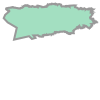

In [ ]:
# Recupera la geometría de la sexta fila (posición 5) de la columna `geometry`
sexta_geometria = gdf_districts.geometry.iloc[5]

sexta_geometria

In [ ]:
# De forma más directa
gdf_districts.geometry[0] # muestra el primer distrito de la columna geometry

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

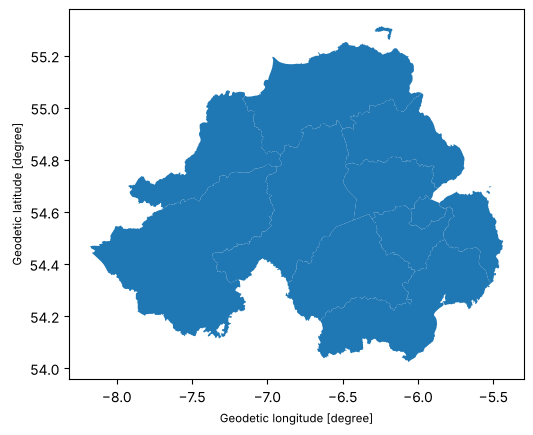

In [ ]:
# Grafica la geometria de los todos los distritos de Irlanda del norte
gdf_districts.plot()

- Revisar las opciones del plot:
https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

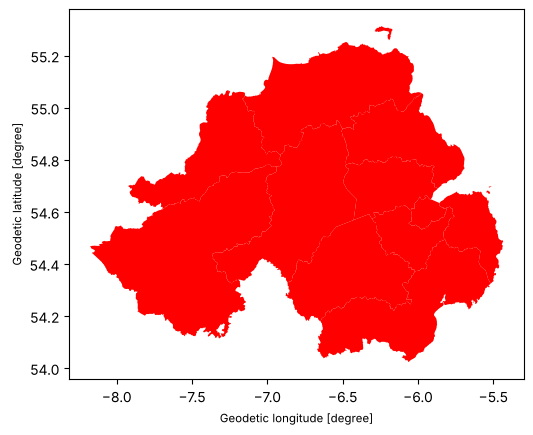

In [ ]:
# Agrega color
gdf_districts.plot(color = 'red')

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

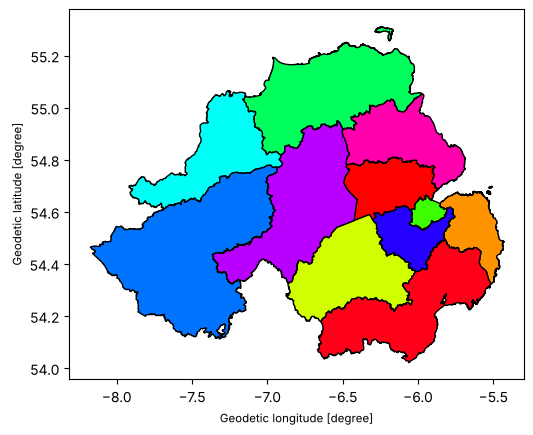

In [ ]:
# Grafica los poligonos del geodataframe pintado
# los bordes de cada distrito
gdf_districts.plot(cmap = 'hsv', edgecolor = 'black', column = 'district')

- Dado que Geopandas esta construido encima de matplotlib, se puede usar los esquemas de colores definidos en el mismo: https://matplotlib.org/stable/tutorials/colors/colormaps.html


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

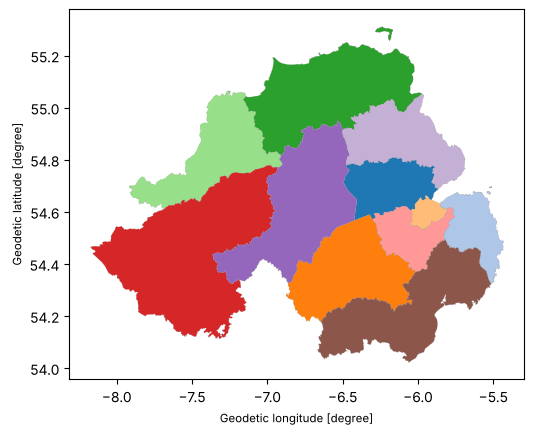

In [ ]:
# Grafica el geodataframe con colores diferenciados por columna district,
#con esquema de colores 'tab20', color de bordes 'gray' y grosor de linea .1
gdf_districts.plot(cmap = 'tab20', edgecolor = 'gray', linewidth = 0.1, column = 'district')  #cmap= tab20,twilight

## Área de estudio

In [ ]:
# carga un geodataframe que contiene un poligono de interes
gdf_area_interest = gpd.read_file('Shapefiles/area_of_interest.shp')
gdf_area_interest.head()

,Id,geometry
0,0,"POLYGON ((-7.10243 54.53227, -7.10175 54.53254..."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

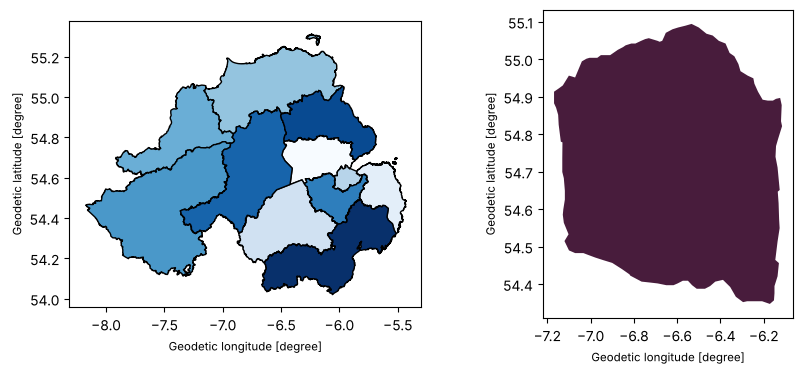

In [ ]:
# Figuras lado a lado: ax1  y  ax2
fig, (ax1, ax2) = plt.subplots(ncols = 2, figsize = (10,4))

# En ax1 poligonos de los distritos
gdf_districts.plot(ax = ax1, cmap = 'Blues', edgecolor = 'black', column = 'district')

# En ax2 el poligono de interés
gdf_area_interest.plot(ax = ax2, color = '#481c3c')

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

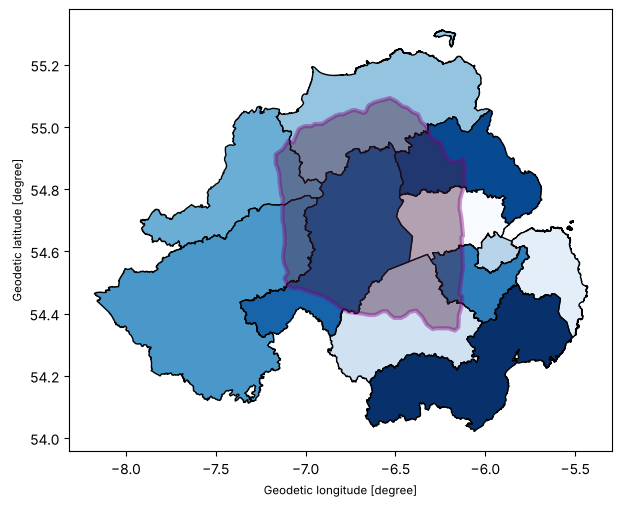

In [ ]:
# Visualizar dos capas espaciales en el mismo mapa:
# 1) capa de distritos
# 2) capa del área de interés
fig, ax = plt.subplots(figsize = (7,7))

# capa de distritos
gdf_districts.plot(ax = ax, cmap = 'Blues', edgecolor = 'black', column = 'district')

# capa de area de interes, alpha = 0.5 --> 50% de transparencia
gdf_area_interest.plot(ax = ax, color = '#481c3c', edgecolor = 'purple', linewidth = 3, alpha = 0.4)

*   Se puede obtener más variedad de colores de Color Brewer: http://colorbrewer2.org



In [ ]:
# Ubicaciones de puntos ATMs (Cajeros Automáticos)
gdf_atms = gpd.read_file('Shapefiles/atms.shp') # puntos ATMs
gdf_atms.head(5)

,operator,geometry
0,Northern Bank,MULTIPOINT ((-6.65841 54.50122))
1,NaN,MULTIPOINT ((-6.22666 54.72956))
2,Bank of Ireland,MULTIPOINT ((-6.22038 54.80819))
3,NaN,MULTIPOINT ((-6.29858 54.43323))
4,NaN,MULTIPOINT ((-6.21401 54.59141))


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

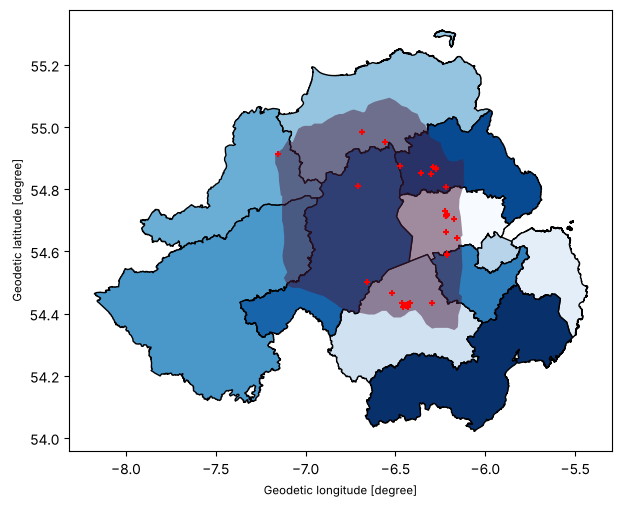

In [ ]:
#Figura con 3 capas: capa de distritos, capa de area de interes  y capa de puntos ATMs
fig, ax = plt.subplots(figsize = (7,7))
gdf_districts.plot(ax = ax, cmap = 'Blues', edgecolor = 'black', column = 'district') # Distritos
gdf_area_interest.plot(ax = ax, color = '#481c3c', alpha = 0.5) #Area de interes
gdf_atms.plot(ax = ax, color = 'red', marker='+', markersize = 16) # Cajeros automáticos

## Sistemas de Coordenadas y Proyecciones


In [ ]:
# Verificar el sistema de coordenadas usado por las geometrías del GeoDataFrame
# El CRS indica cómo interpretar las coordenadas espaciales, por ejemplo, latitud/longitud o coordenadas proyectadas.
gdf_districts.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

Sistemas de coordenadas populares:
- https://epsg.io/4326 Sistema geográfico usado por GPS (WGS84). Unidades en **grados**.
- https://epsg.io/32629 UTM zona 29N: sistema proyectado. Unidades en **metros**. Es la zona UTM que corresponde a Irlanda del Norte.

No hace falta buscar la zona a mano: `estimate_utm_crs()` la elige según la ubicación de los datos (igual que en el laboratorio del lunes con Lima, que dio la zona 18S).

In [ ]:
# estimate_utm_crs() sugiere la zona UTM adecuada para estos datos
crs_metros = gdf_districts.estimate_utm_crs()
print(crs_metros)   # EPSG:32629 = UTM zona 29N

# .to_crs reproyecta el geodataframe al nuevo sistema de coordenadas:
# de grados (longitud, latitud) a metros
gdf_districts_new = gdf_districts.to_crs(crs_metros)
gdf_districts_new

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
gdf_districts_new.crs

<Projected CRS: EPSG:32629>
Name: WGS 84 / UTM zone 29N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 12°W and 6°W, northern hemisphere between equator and 84°N, onshore and offshore. Algeria. Côte D'Ivoire (Ivory Coast). Faroe Islands. Guinea. Ireland. Jan Mayen. Liberia, Mali. Mauritania. Morocco. Portugal. Sierra Leone. Spain. United Kingdom (UK). Western Sahara.
- bounds: (-12.01, 0.0, -6.0, 84.01)
Coordinate Operation:
- name: UTM zone 29N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

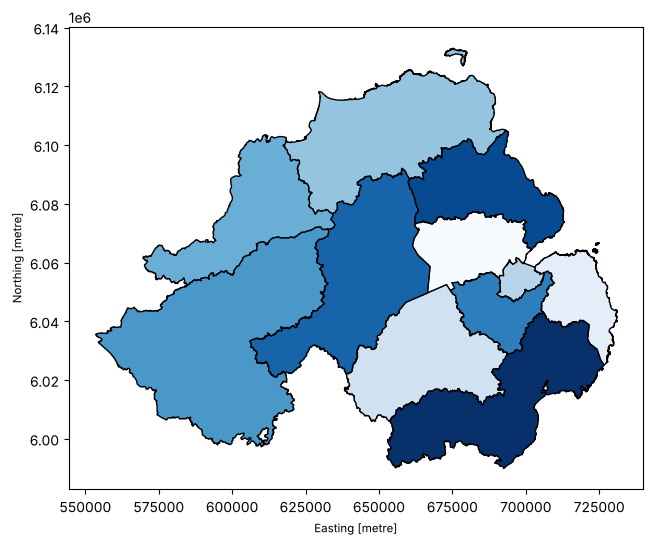

In [ ]:
# Grafica el  geodataframe de distritos reproyectado en coordenadas cartesianas
fig, ax = plt.subplots(figsize = (8,6))
gdf_districts_new.plot(ax = ax, cmap = 'Blues', edgecolor = 'black', column = 'district')

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

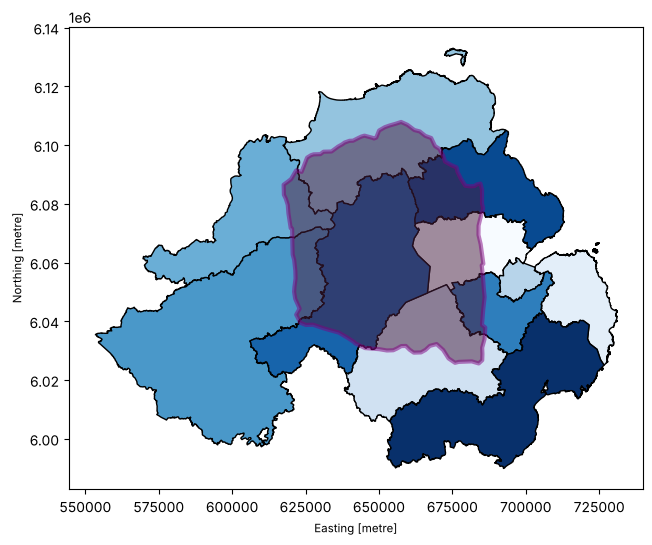

In [ ]:
# Grafica el  geodataframe de distritos y area de interes  reproyectados en el sistema de coordenadas cartesianas
fig, ax = plt.subplots(figsize = (8,6))
gdf_districts_new.plot(ax = ax, cmap = 'Blues', edgecolor = 'black', column = 'district')   # Capa de distritos reproyectada

gdf_area_interest_new = gdf_area_interest.to_crs(gdf_districts_new.crs)  # Area de interes reproyectada al mismo CRS que los distritos
gdf_area_interest_new.plot(ax = ax, color = '#481c3c', alpha = 0.5, edgecolor = 'purple',linewidth = 3)  # Area de interes con transparencia

## Interseccion entre capas

* `overlay` usa internamente un **índice espacial** para encontrar rápido qué geometrías se cruzan, en lugar de comparar todas contra todas. GeoPandas ya lo trae incluido: no hace falta instalar nada.
* Importante: **las dos capas deben estar en el mismo CRS**. Por eso usamos las versiones reproyectadas a metros.

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

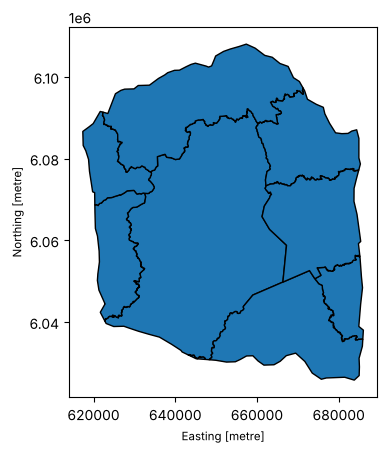

In [ ]:
# Intersectar la capa de distritos con la capa del área de interés.
# El resultado conserva únicamente las partes de los distritos que caen dentro del área de interés.

gdf_districts_in_area = gpd.overlay(gdf_districts_new, gdf_area_interest_new, how = 'intersection')
gdf_districts_in_area.plot(edgecolor = 'black')  # plotea el geodataframe extraido

In [ ]:
gdf_districts_in_area.head()

,district,Id,geometry
0,Mid Ulster,0,"POLYGON ((658023.63 6091903.404, 658030.243 60..."
1,Mid and East Antrim,0,"POLYGON ((684908.771 6077240.941, 684903.541 6..."
2,Lisburn and Castlereagh,0,"POLYGON ((685894.09 6035737.164, 685891.166 60..."
3,"Armagh City, Banbridge and Craigavon",0,"MULTIPOLYGON (((676033.306 6048080.158, 676033..."
4,Antrim and Newtownabbey,0,"POLYGON ((682239.947 6077405.626, 682246.748 6..."


In [ ]:
# Calcular el área de cada porción de distrito resultante de la intersección.
# Como el GeoDataFrame está en un CRS proyectado en metros, el área se obtiene en m².
# Se divide entre 1 000 000 para convertir el área a km².

gdf_districts_in_area['area_km2'] = gdf_districts_in_area.area/1000000
gdf_districts_in_area.head(5)

,district,Id,geometry,area_km2
0,Mid Ulster,0,"POLYGON ((658023.63 6091903.404, 658030.243 60...",1574.420076
1,Mid and East Antrim,0,"POLYGON ((684908.771 6077240.941, 684903.541 6...",373.691057
2,Lisburn and Castlereagh,0,"POLYGON ((685894.09 6035737.164, 685891.166 60...",151.737874
3,"Armagh City, Banbridge and Craigavon",0,"MULTIPOLYGON (((676033.306 6048080.158, 676033...",553.932816
4,Antrim and Newtownabbey,0,"POLYGON ((682239.947 6077405.626, 682246.748 6...",462.822918
